# NHS Waiting Lists: Exploratory Analysis

Exploratory analysis behind **HealthQueue GPT**. Two datasets with the same core structure (patients waiting, by waiting-time band, per organisation):

1. **Real:** NHS England Referral-to-Treatment (RTT) waiting times, February 2025 (`data/WLMDS-Summary-to-23-Feb-2025_2.1.csv`).
2. **Synthetic:** a 100-organisation RTT-style dataset with a simulated patient-satisfaction column (`data/synthetic_waiting_list_data_with_satisfaction.csv`).

Run from the repository root. Figures are written to `figures/`.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs('figures', exist_ok=True)
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.width', 140)

BANDS = ['0 to 18 weeks', '18 to 26 weeks', '26 to 40 weeks', '40 to 52 weeks',
         '52 to 65 weeks', '65 to 78 weeks', '78 to 104 weeks', '104+ weeks']

## 1. Load and clean

The real file is semicolon-delimited and uses `.` as a **thousands separator** (`14.261` means 14,261), mixed with plain integers. Parsing it as ordinary numbers silently turns thousands into decimals. The loader below reads every column as text first, strips the separator, then converts.

In [2]:
def load_real(path):
    df = pd.read_csv(path, sep=';', dtype=str)
    df.columns = df.columns.str.strip()
    for c in df.columns[3:]:
        df[c] = pd.to_numeric(df[c].str.replace('.', '', regex=False), errors='raise')
    return df

def load_synthetic(path):
    df = pd.read_csv(path)
    df.columns = df.columns.str.strip()
    return df

real = load_real('data/WLMDS-Summary-to-23-Feb-2025_2.1.csv')
synth = load_synthetic('data/synthetic_waiting_list_data_with_satisfaction.csv')
real['Total Waiting'] = real[BANDS].sum(axis=1)
synth['Total Waiting'] = synth[BANDS].sum(axis=1)

print('real  :', real.shape, '| organisations:', real['Organisation Code'].nunique())
print('synth :', synth.shape)

real  : (613, 18) | organisations: 613
synth : (100, 16)


In [3]:
# Why the separator matters: the same column, parsed naively vs correctly
naive = pd.read_csv('data/WLMDS-Summary-to-23-Feb-2025_2.1.csv', sep=';', decimal=',')['Total Waiting List']
naive = pd.to_numeric(naive, errors='coerce')
print(f"Total Waiting List, naive parse : {naive.sum():>12,.0f}")
print(f"Total Waiting List, cleaned     : {real['Total Waiting List'].sum():>12,.0f}")

Total Waiting List, naive parse :      106,066
Total Waiting List, cleaned     :    7,408,975


### Sanity checks

In [4]:
gap = real['Total Waiting List'] - real['Total Waiting Sum'] if 'Total Waiting Sum' in real else real['Total Waiting List'] - real['Total Waiting']
print('Rows where the eight bands do not add up to Total Waiting List:', int((gap != 0).sum()), 'of', len(real))
print('Sum of those gaps:', int(gap.sum()), '| Unknown Clock Start Date total:', int(real['Unknown Clock Start Date'].sum()))
print('Organisations with an empty waiting list:', int((real['Total Waiting'] == 0).sum()))
print()
print('Organisation types (real):'); print(real['Organisation Type'].value_counts().to_string())
print()
print('Odd organisation codes (synthetic):',
      synth.loc[~synth['Organisation Code'].astype(str).str.fullmatch(r'[A-Z]{3}\d{3}'), 'Organisation Code'].tolist())

Rows where the eight bands do not add up to Total Waiting List: 81 of 613
Sum of those gaps: 5199 | Unknown Clock Start Date total: 5199
Organisations with an empty waiting list: 18

Organisation types (real):
Organisation Type
INDEPENDENT SECTOR H/C PROVIDER SITE      441
ACUTE TRUST                               134
INDEPENDENT SECTOR HEALTHCARE PROVIDER     25
COMMUNITY TRUST                            10
MENTAL HEALTH AND LEARNING DISABILITY       2
Unknown Provider                            1

Odd organisation codes (synthetic): ['198,00\xa0MAD']


## 2. Real NHS data (February 2025)

### 2.1 Where is the waiting list?

,organisations,waiting,share_%
Organisation Type,,,
ACUTE TRUST,134,6996283,94.5
INDEPENDENT SECTOR H/C PROVIDER SITE,441,355452,4.8
COMMUNITY TRUST,10,37501,0.5
INDEPENDENT SECTOR HEALTHCARE PROVIDER,25,9720,0.1
MENTAL HEALTH AND LEARNING DISABILITY,2,3916,0.1
Unknown Provider,1,904,0.0


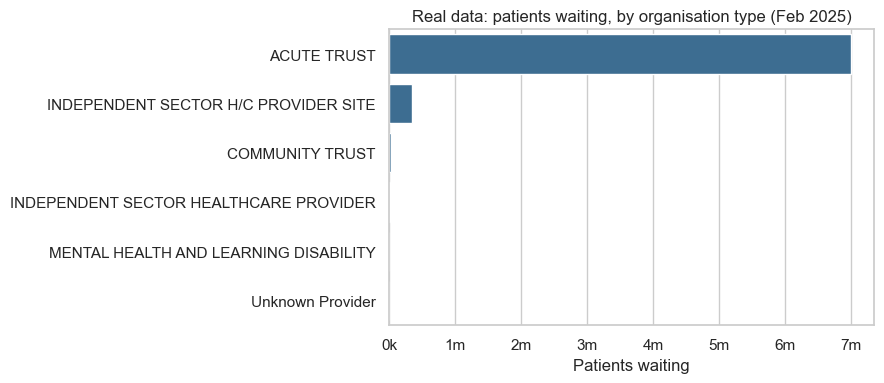

In [5]:
by_type = (real.groupby('Organisation Type')
               .agg(organisations=('Organisation Code', 'count'), waiting=('Total Waiting', 'sum'))
               .sort_values('waiting', ascending=False))
by_type['share_%'] = (by_type['waiting'] / by_type['waiting'].sum() * 100).round(1)
display(by_type)

fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(x=by_type['waiting'], y=by_type.index, color='#2f6f9f', ax=ax)
ax.set_title('Real data: patients waiting, by organisation type (Feb 2025)')
ax.set_xlabel('Patients waiting'); ax.set_ylabel('')
ax.xaxis.set_major_formatter(lambda v, _: f'{v/1e6:.0f}m' if v >= 1e6 else f'{v/1e3:.0f}k')
fig.tight_layout(); fig.savefig('figures/real_waiting_by_type.png', dpi=150); plt.show()

### 2.2 How long are they waiting?

                 patients  share_%
0 to 18 weeks     4305571    58.15
18 to 26 weeks    1098073    14.83
26 to 40 weeks    1239486    16.74
40 to 52 weeks     553178     7.47
52 to 65 weeks     190439     2.57
65 to 78 weeks      15309     0.21
78 to 104 weeks      1608     0.02
104+ weeks            112     0.00

Within 18 weeks : 58.1%  (NHS constitutional standard: 92%)
Over 52 weeks   : 207,468 patients (2.8%)
Over 78 weeks   : 1,720 patients | 104+ weeks: 112


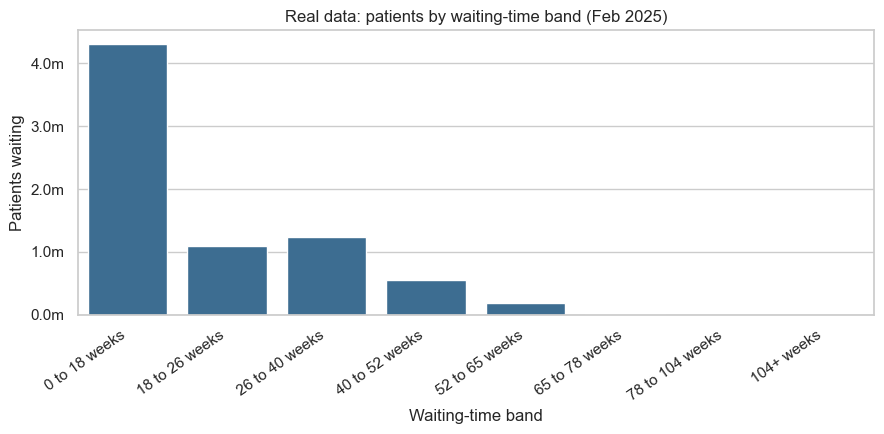

In [6]:
bands_real = real[BANDS].sum()
share = (bands_real / bands_real.sum() * 100).round(2)
print(pd.DataFrame({'patients': bands_real, 'share_%': share}).to_string())
print()
print(f"Within 18 weeks : {share.iloc[0]:.1f}%  (NHS constitutional standard: 92%)")
print(f"Over 52 weeks   : {bands_real.iloc[4:].sum():,} patients ({bands_real.iloc[4:].sum()/bands_real.sum()*100:.1f}%)")
print(f"Over 78 weeks   : {bands_real.iloc[6:].sum():,} patients | 104+ weeks: {bands_real.iloc[7]:,}")

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(x=bands_real.index, y=bands_real.values, color='#2f6f9f', ax=ax)
ax.set_title('Real data: patients by waiting-time band (Feb 2025)')
ax.set_xlabel('Waiting-time band'); ax.set_ylabel('Patients waiting')
ax.yaxis.set_major_formatter(lambda v, _: f'{v/1e6:.1f}m')
plt.setp(ax.get_xticklabels(), rotation=35, ha='right')
fig.tight_layout(); fig.savefig('figures/real_patients_by_band.png', dpi=150); plt.show()

### 2.3 Do NHS trusts and independent providers differ?

In [7]:
perf = (real.groupby('Organisation Type')
            .apply(lambda d: pd.Series({
                'organisations': len(d),
                'within_18w_%': d['0 to 18 weeks'].sum() / d['Total Waiting'].sum() * 100,
                'over_52w_%': d[BANDS[4:]].sum().sum() / d['Total Waiting'].sum() * 100}),
                include_groups=False)
            .round(1).sort_values('organisations', ascending=False))
display(perf)

,organisations,within_18w_%,over_52w_%
Organisation Type,,,
INDEPENDENT SECTOR H/C PROVIDER SITE,441.0,74.8,1.1
ACUTE TRUST,134.0,57.2,2.9
INDEPENDENT SECTOR HEALTHCARE PROVIDER,25.0,82.1,0.5
COMMUNITY TRUST,10.0,71.8,1.9
MENTAL HEALTH AND LEARNING DISABILITY,2.0,93.7,0.1
Unknown Provider,1.0,99.9,0.0


In [8]:
top = real.nlargest(10, 'Total Waiting')[['Organisation Name', 'Organisation Type', 'Total Waiting']]
display(top.assign(**{'Total Waiting': top['Total Waiting'].map('{:,}'.format)}).reset_index(drop=True))

,Organisation Name,Organisation Type,Total Waiting
0,MANCHESTER UNIVERSITY NHS FOUNDATION TRUST,ACUTE TRUST,"200,407"
1,MID AND SOUTH ESSEX NHS FOUNDATION TRUST,ACUTE TRUST,"165,893"
2,ROYAL FREE LONDON NHS FOUNDATION TRUST,ACUTE TRUST,"147,431"
3,NORTHERN CARE ALLIANCE NHS FOUNDATION TRUST,ACUTE TRUST,"138,518"
4,GUY'S AND ST THOMAS' NHS FOUNDATION TRUST,ACUTE TRUST,"125,148"
5,BARTS HEALTH NHS TRUST,ACUTE TRUST,"124,396"
6,UNIVERSITY HOSPITALS SUSSEX NHS FOUNDATION TRUST,ACUTE TRUST,"116,775"
7,UNIVERSITY HOSPITALS BIRMINGHAM NHS FOUNDATION...,ACUTE TRUST,"112,160"
8,UNIVERSITY HOSPITALS OF LEICESTER NHS TRUST,ACUTE TRUST,"109,798"
9,UNIVERSITY HOSPITALS OF DERBY AND BURTON NHS F...,ACUTE TRUST,"108,382"


### 2.4 Correlations between bands

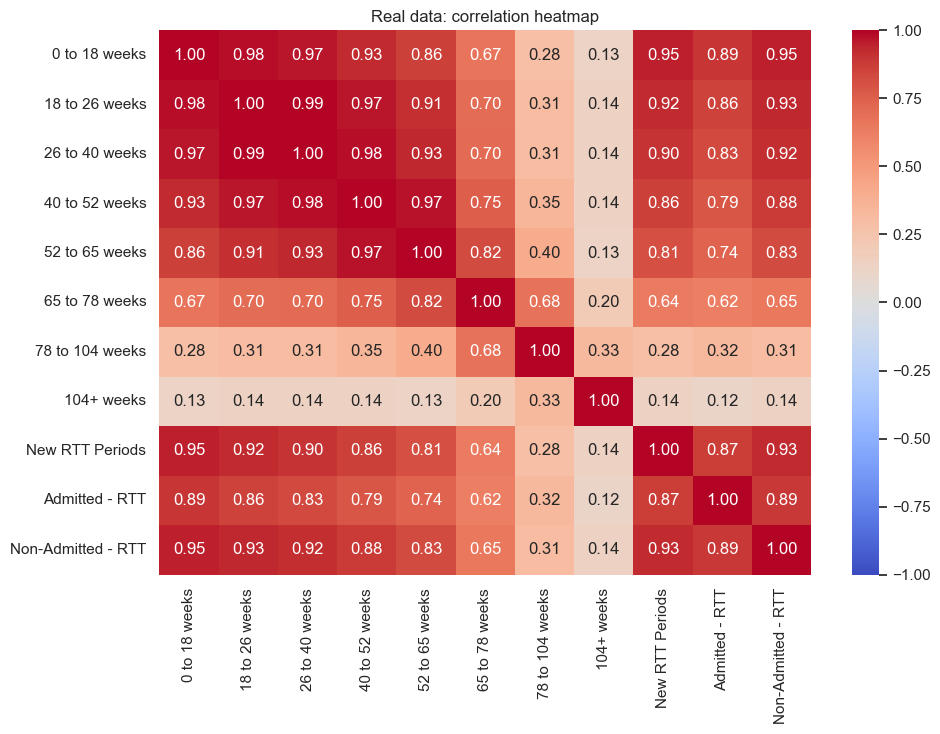

In [9]:
cols = BANDS + ['New RTT Periods', 'Admitted - RTT', 'Non-Admitted - RTT']
fig, ax = plt.subplots(figsize=(10, 7.5))
sns.heatmap(real[cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax)
ax.set_title('Real data: correlation heatmap')
fig.tight_layout(); fig.savefig('figures/real_correlation.png', dpi=150); plt.show()

## 3. Synthetic data (with patient satisfaction)

### 3.1 Waiting list size and shape

,organisations,waiting,share_%
Organisation Type,,,
ACUTE TRUST,25,122434,74.2
INDEPENDENT SECTOR H/C PROVIDER SITE,72,39662,24.0
COMMUNITY TRUST,1,2092,1.3
INDEPENDENT SECTOR HEALTHCARE PROVIDER,2,925,0.6


                 patients  share_%
0 to 18 weeks       70973    42.98
18 to 26 weeks      33109    20.05
26 to 40 weeks      31809    19.26
40 to 52 weeks      20826    12.61
52 to 65 weeks       7586     4.59
65 to 78 weeks        683     0.41
78 to 104 weeks        85     0.05
104+ weeks             42     0.03

Within 18 weeks: 43.0%   Over 52 weeks: 5.1%


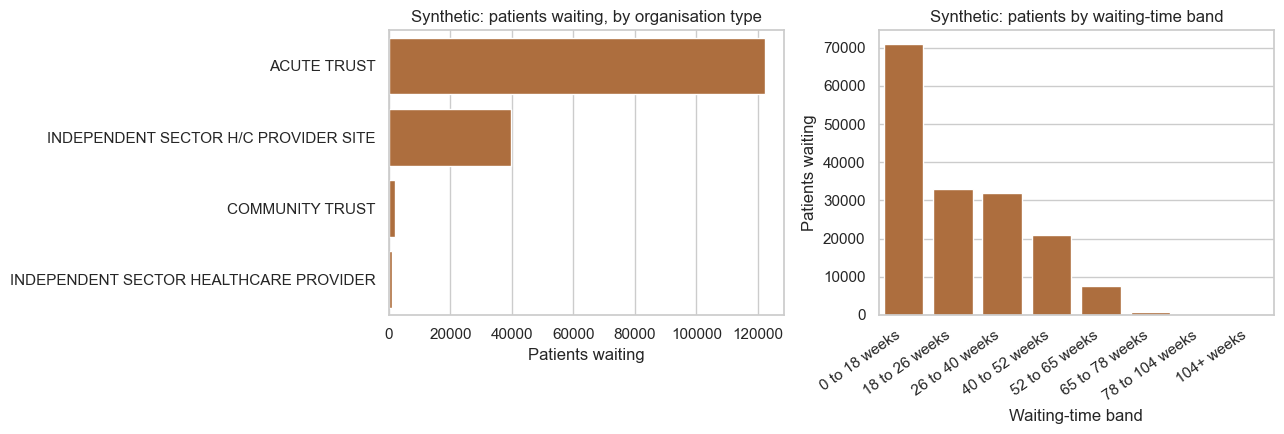

In [10]:
by_type_s = (synth.groupby('Organisation Type')
                  .agg(organisations=('Organisation Code', 'count'), waiting=('Total Waiting', 'sum'))
                  .sort_values('waiting', ascending=False))
by_type_s['share_%'] = (by_type_s['waiting'] / by_type_s['waiting'].sum() * 100).round(1)
display(by_type_s)

bands_s = synth[BANDS].sum()
share_s = (bands_s / bands_s.sum() * 100).round(2)
print(pd.DataFrame({'patients': bands_s, 'share_%': share_s}).to_string())
print(f"\nWithin 18 weeks: {share_s.iloc[0]:.1f}%   Over 52 weeks: {bands_s.iloc[4:].sum()/bands_s.sum()*100:.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.barplot(x=by_type_s['waiting'], y=by_type_s.index, color='#c06c2b', ax=axes[0])
axes[0].set_title('Synthetic: patients waiting, by organisation type'); axes[0].set_xlabel('Patients waiting'); axes[0].set_ylabel('')
sns.barplot(x=bands_s.index, y=bands_s.values, color='#c06c2b', ax=axes[1])
axes[1].set_title('Synthetic: patients by waiting-time band'); axes[1].set_xlabel('Waiting-time band'); axes[1].set_ylabel('Patients waiting')
plt.setp(axes[1].get_xticklabels(), rotation=35, ha='right')
fig.tight_layout(); fig.savefig('figures/synthetic_type_and_band.png', dpi=150); plt.show()

### 3.2 Correlations

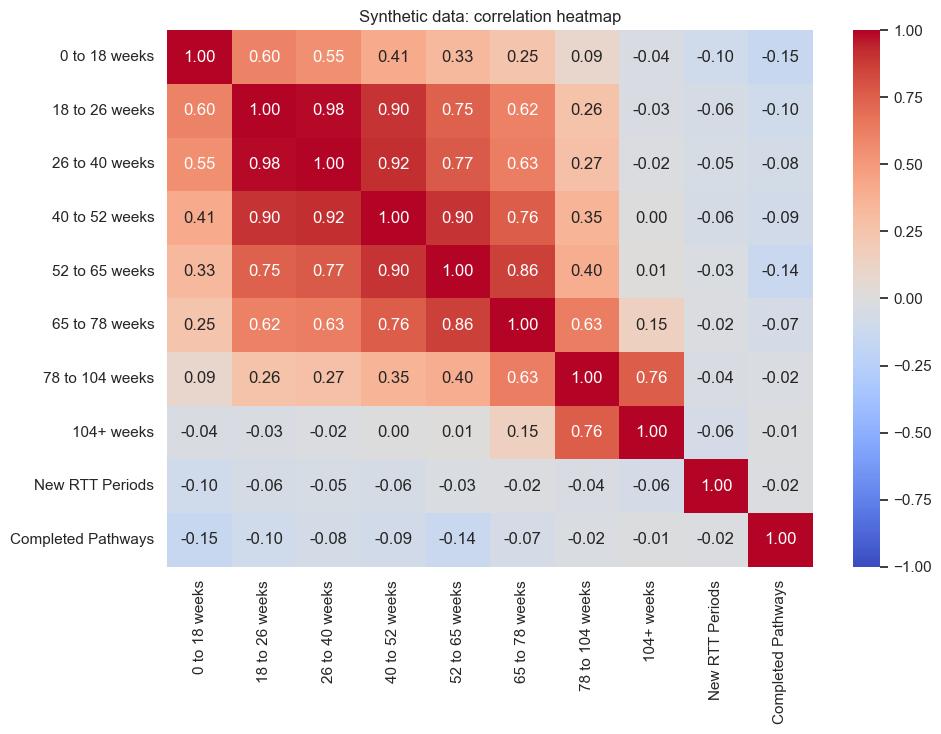

Correlation of Completed Pathways with each waiting band:
0 to 18 weeks     -0.15
18 to 26 weeks    -0.10
26 to 40 weeks    -0.08
40 to 52 weeks    -0.09
52 to 65 weeks    -0.14
65 to 78 weeks    -0.07
78 to 104 weeks   -0.02
104+ weeks        -0.01


In [11]:
cols_s = BANDS + ['New RTT Periods', 'Completed Pathways']
corr_s = synth[cols_s].corr()
fig, ax = plt.subplots(figsize=(10, 7.5))
sns.heatmap(corr_s, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax)
ax.set_title('Synthetic data: correlation heatmap')
fig.tight_layout(); fig.savefig('figures/synthetic_correlation.png', dpi=150); plt.show()

print('Correlation of Completed Pathways with each waiting band:')
print(corr_s.loc[BANDS, 'Completed Pathways'].round(2).to_string())

Completed pathways are **not** positively related to the waiting bands in this dataset: the correlations are weak and slightly negative. The synthetic file was not built with a link between waiting times and completions, so no such relationship should be read into it.

### 3.3 Patient satisfaction vs waiting time

The satisfaction column was simulated and added to RTT-style data. This checks whether it behaves like it is linked to waiting.

,organisations,median_waiting,mean_pct_within_18w
Patient Satisfaction,,,
Very Dissatisfied,24,308.5,65.7
Dissatisfied,22,104.5,79.4
Neutral,15,1096.0,69.8
Satisfied,13,531.0,76.5
Very Satisfied,26,676.5,69.9


Spearman, satisfaction vs Total Waiting   : +0.17
Spearman, satisfaction vs pct_within_18w  : -0.00
Spearman, satisfaction vs pct_over_52w    : -0.03


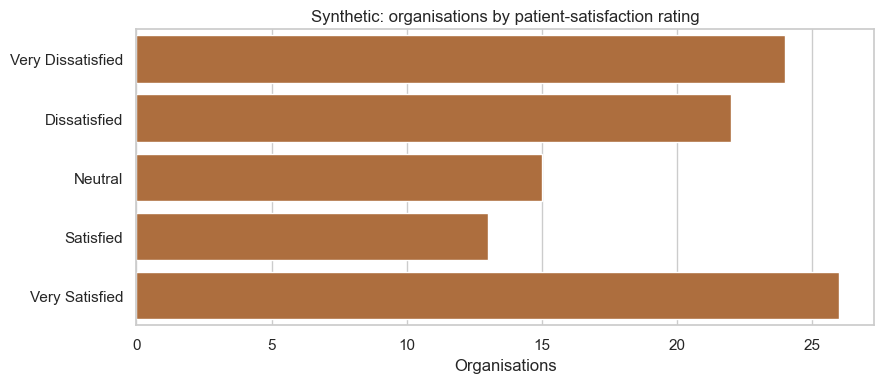

In [12]:
order = ['Very Dissatisfied', 'Dissatisfied', 'Neutral', 'Satisfied', 'Very Satisfied']
score = {k: i + 1 for i, k in enumerate(order)}
synth['satisfaction_score'] = synth['Patient Satisfaction'].map(score)
synth['pct_within_18w'] = synth['0 to 18 weeks'] / synth['Total Waiting'].replace(0, np.nan) * 100
synth['pct_over_52w'] = synth[BANDS[4:]].sum(axis=1) / synth['Total Waiting'].replace(0, np.nan) * 100

summary = (synth.groupby('Patient Satisfaction')
                .agg(organisations=('Organisation Code', 'count'),
                     median_waiting=('Total Waiting', 'median'),
                     mean_pct_within_18w=('pct_within_18w', 'mean'))
                .reindex(order).round(1))
display(summary)

for col in ['Total Waiting', 'pct_within_18w', 'pct_over_52w']:
    rho = synth['satisfaction_score'].corr(synth[col], method='spearman')
    print(f'Spearman, satisfaction vs {col:<16}: {rho:+.2f}')

fig, ax = plt.subplots(figsize=(9, 4))
sns.countplot(y='Patient Satisfaction', data=synth, order=order, color='#c06c2b', ax=ax)
ax.set_title('Synthetic: organisations by patient-satisfaction rating'); ax.set_xlabel('Organisations'); ax.set_ylabel('')
fig.tight_layout(); fig.savefig('figures/synthetic_satisfaction.png', dpi=150); plt.show()

Satisfaction shows no relationship with how long patients wait: the rank correlations with the share seen within 18 weeks and the share over 52 weeks are essentially zero. The one weak signal is with list size (+0.17), which is not meaningful with 100 organisations. So the dataset supports *descriptive* questions ("which hospitals have the highest satisfaction?") but not claims that waiting drives satisfaction.

## 4. Takeaways

- The real data confirms the headline picture for February 2025: a waiting list of roughly 7.4 million, with just under 60% of patients inside 18 weeks, far short of the 92% standard, and about 2.8% waiting over a year.
- Acute trusts hold the overwhelming majority of the list; independent-sector sites are far more numerous but small, and show a higher share of patients seen within 18 weeks.
- The synthetic dataset has a similar shape but should be treated as illustrative only.